# Stage 4.6 — Stratified 5-Fold Model Stability

This Notebook evaluates coefficient and predictive stability for the fixed ten-variable Candidate WOE Logistic using one deterministic five-fold assignment inside the 24,000-row Development Train.

Boundaries: frozen predictors and bins; Fold-Train-only WOE; exactly five unpenalized MLE fold models; no variable deletion, re-binning, alternative subset, regularization, class weighting/resampling, calibration, operational threshold optimization, or Holdout predictive analysis. All ten predictors continue to Stage 4.7 when all folds are methodologically and numerically valid.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
sns.set_theme(style="whitegrid", context="notebook")

TARGET = "default.payment.next.month"
ID_COL = "ID"
RANDOM_STATE = 42
TEST_SIZE = 0.20
EXPECTED_TRAIN_HASH = "bcb37af63ae7005df78e6140837594b5d650d27148b46b5d51354430ad958857"
EXPECTED_TEST_HASH = "d6748249f9f9fb2855746e0ed980b5013047267104090a14aa8138a700fe6f0f"
FINAL_PREDICTORS = [
    "PAY_0", "severe_delinquent_months",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
    "LIMIT_BAL", "avg_utilization",
]
PAY_VARIABLES = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_VARIABLES = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT_VARIABLES = [f"PAY_AMT{i}" for i in range(1, 7)]
STAGE45_COEFFICIENTS = {
    "PAY_0": -0.5563037015799417,
    "severe_delinquent_months": -0.5130600457203316,
    "PAY_AMT1": -0.19375556909635522,
    "PAY_AMT2": -0.22209268793186335,
    "PAY_AMT3": -0.2454014385336965,
    "PAY_AMT4": -0.16504179381780898,
    "PAY_AMT5": -0.09712243714942834,
    "PAY_AMT6": -0.1643491017035289,
    "LIMIT_BAL": -0.22616064220106788,
    "avg_utilization": -0.40562115775846636,
}
STAGE45_STATUS = {name: ("Review in Stage 4.6" if name == "PAY_AMT5" else "Directionally Clear") for name in FINAL_PREDICTORS}
STAGE45_APPARENT_AUC = 0.772417098
STAGE45_APPARENT_KS = 0.430307867
assert list(STAGE45_COEFFICIENTS) == FINAL_PREDICTORS
assert len(FINAL_PREDICTORS) == len(set(FINAL_PREDICTORS)) == 10

def locate_project_root():
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / "data/raw/UCI_Credit_Card.csv").is_file():
            return candidate
    raise FileNotFoundError("Formal raw CSV not found from launch path or its parents.")

def stable_id_hash(values):
    canonical = "\n".join(str(int(value)) for value in sorted(values))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

project_root = locate_project_root()
data_path = project_root / "data/raw/UCI_Credit_Card.csv"
environment_table = pd.DataFrame({"Value": [
    sys.executable, sys.version.split()[0], metadata.version("pandas"), metadata.version("numpy"),
    metadata.version("scipy"), metadata.version("scikit-learn"), metadata.version("matplotlib"),
    metadata.version("seaborn"), metadata.version("statsmodels"),
]}, index=[
    "Python executable", "Python version", "pandas", "numpy", "scipy", "scikit-learn",
    "matplotlib", "seaborn", "statsmodels",
])
display(environment_table)
print("Project root:", project_root)
print("Frozen candidate order:", FINAL_PREDICTORS)


,Value
Python executable,/opt/anaconda3/bin/python
Python version,3.11.7
pandas,2.1.4
numpy,1.26.4
scipy,1.11.4
scikit-learn,1.2.2
matplotlib,3.8.0
seaborn,0.12.2
statsmodels,0.14.0


Project root: /Users/yu/2.工作/Risk Analysis Project
Frozen candidate order: ['PAY_0', 'severe_delinquent_months', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'LIMIT_BAL', 'avg_utilization']


## 1. Frozen outer Train/Holdout split and immediate Holdout sealing

Holdout Test is used only for row count, ID overlap, ID union coverage, and frozen ID hash. No Holdout predictor, target distribution, bin occupancy, WOE, coefficient, probability, performance, calibration, or risk relationship is inspected.


In [2]:
raw_df = pd.read_csv(data_path)
assert raw_df.shape == (30000, 25) and raw_df[ID_COL].is_unique

development_raw, sealed_holdout = train_test_split(
    raw_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=raw_df[TARGET],
)
development_ids = set(development_raw[ID_COL].astype(int))
holdout_ids = set(sealed_holdout[ID_COL].astype(int))
full_ids = set(raw_df[ID_COL].astype(int))
train_hash = stable_id_hash(development_ids)
test_hash = stable_id_hash(holdout_ids)
id_overlap = len(development_ids & holdout_ids)
id_union_complete = development_ids | holdout_ids == full_ids

assert len(development_raw) == 24000 and len(sealed_holdout) == 6000
assert id_overlap == 0 and id_union_complete
assert train_hash == EXPECTED_TRAIN_HASH and test_hash == EXPECTED_TEST_HASH

outer_split_evidence = pd.DataFrame({"Actual": [
    30000, len(development_raw), len(sealed_holdout), id_overlap, id_union_complete, train_hash, test_hash,
]}, index=[
    "Raw rows", "Development Train rows", "Holdout rows", "ID overlap", "Full ID union coverage",
    "Train ID SHA-256", "Test ID SHA-256",
])
display(outer_split_evidence)

del sealed_holdout, holdout_ids, full_ids, raw_df
HOLDOUT_SEAL_STATUS = "SEALED — Holdout deleted after row/ID/union/hash identity checks only"
print(HOLDOUT_SEAL_STATUS)

DEVELOPMENT_GOOD = int((development_raw[TARGET] == 0).sum())
DEVELOPMENT_BAD = int((development_raw[TARGET] == 1).sum())
DEVELOPMENT_BAD_RATE = DEVELOPMENT_BAD / len(development_raw)
assert (DEVELOPMENT_GOOD, DEVELOPMENT_BAD) == (18691, 5309)
print(f"Development target: Good={DEVELOPMENT_GOOD:,}; Bad={DEVELOPMENT_BAD:,}; Bad rate={DEVELOPMENT_BAD_RATE:.6%}")


,Actual
Raw rows,30000
Development Train rows,24000
Holdout rows,6000
ID overlap,0
Full ID union coverage,True
Train ID SHA-256,bcb37af63ae7005df78e6140837594b5d650d27148b46b...
Test ID SHA-256,d6748249f9f9fb2855746e0ed980b5013047267104090a...


SEALED — Holdout deleted after row/ID/union/hash identity checks only
Development target: Good=18,691; Bad=5,309; Bad rate=22.120833%


## 2. Frozen feature and bin definitions

Only the two required deterministic Stage 3 features are reproduced within each fold input:

\[
severe\_delinquent\_months=\sum_i 1(PAY_i\ge2)
\]

\[
avg\_utilization=\frac{mean(max(BILL\_AMT1,0),\ldots,max(BILL\_AMT6,0))}{LIMIT\_BAL}
\]

Utilization above 1 remains uncapped. The Stage 4.2/4.3 bin boundaries below are fixed globally; no fold target or Validation observation changes a boundary.


In [3]:
PAY_DOMAIN = set(range(-2, 9))
PAY0_MAP = {
    -2: "[-2,-1,0]", -1: "[-2,-1,0]", 0: "[-2,-1,0]", 1: "[1]",
    2: "[2+]", 3: "[2+]", 4: "[2+]", 5: "[2+]", 6: "[2+]", 7: "[2+]", 8: "[2+]",
}

def engineer_required_features(raw_predictor_input):
    assert TARGET not in raw_predictor_input.columns
    assert ID_COL in raw_predictor_input.columns
    required = PAY_VARIABLES + BILL_VARIABLES + PAY_AMT_VARIABLES + ["LIMIT_BAL", ID_COL]
    source_before = raw_predictor_input[required].copy(deep=True)
    work = raw_predictor_input.copy(deep=True)
    work["severe_delinquent_months"] = (work[PAY_VARIABLES] >= 2).sum(axis=1).astype("int64")
    assert (work["LIMIT_BAL"] > 0).all()
    calculation_only_positive_bills = work[BILL_VARIABLES].clip(lower=0)
    work["avg_utilization"] = calculation_only_positive_bills.mean(axis=1) / work["LIMIT_BAL"]
    del calculation_only_positive_bills
    pd.testing.assert_frame_equal(work[required], source_before, check_exact=True)
    assert work[["severe_delinquent_months", "avg_utilization"]].notna().all().all()
    assert np.isfinite(work["avg_utilization"]).all() and (work["avg_utilization"] >= 0).all()
    return work

def finite_number(value, name):
    if pd.isna(value) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise ValueError(f"{name}: invalid input")
    numeric = float(value)
    if not np.isfinite(numeric):
        raise ValueError(f"{name}: non-finite input")
    return numeric

def map_pay_0(value):
    numeric = finite_number(value, "PAY_0")
    raw = int(numeric)
    if raw != numeric or raw not in PAY_DOMAIN:
        raise ValueError("PAY_0 outside approved integer domain -2 through 8")
    return PAY0_MAP[raw]

def map_severe(value):
    numeric = finite_number(value, "severe_delinquent_months")
    raw = int(numeric)
    mapping = {0: "0", 1: "1", 2: "2", 3: "3", 4: "4+", 5: "4+", 6: "4+"}
    if raw != numeric or raw not in mapping:
        raise ValueError("severe_delinquent_months outside approved integer domain 0 through 6")
    return mapping[raw]

def map_payment(value):
    numeric = finite_number(value, "PAY_AMT")
    if numeric < 0:
        raise ValueError("negative PAY_AMT outside approved domain")
    if numeric == 0:
        return "0"
    if numeric <= 5000:
        return "(0,5k]"
    if numeric <= 20000:
        return "(5k,20k]"
    return ">20k"

def map_limit(value):
    numeric = finite_number(value, "LIMIT_BAL")
    if numeric <= 30000:
        return "<=30k"
    if numeric <= 140000:
        return "(30k,140k]"
    if numeric <= 240000:
        return "(140k,240k]"
    return ">240k"

def map_utilization(value):
    numeric = finite_number(value, "avg_utilization")
    if numeric < 0:
        raise ValueError("negative utilization outside approved domain")
    if numeric == 0:
        return "0"
    if numeric <= 0.20:
        return "(0,0.2]"
    if numeric <= 0.60:
        return "(0.2,0.6]"
    if numeric <= 1:
        return "(0.6,1]"
    return ">1"

BIN_ORDERS = {
    "PAY_0": ["[-2,-1,0]", "[1]", "[2+]"],
    "severe_delinquent_months": ["0", "1", "2", "3", "4+"],
    **{name: ["0", "(0,5k]", "(5k,20k]", ">20k"] for name in PAY_AMT_VARIABLES},
    "LIMIT_BAL": ["<=30k", "(30k,140k]", "(140k,240k]", ">240k"],
    "avg_utilization": ["0", "(0,0.2]", "(0.2,0.6]", "(0.6,1]", ">1"],
}
BIN_MAPPERS = {
    "PAY_0": map_pay_0,
    "severe_delinquent_months": map_severe,
    **{name: map_payment for name in PAY_AMT_VARIABLES},
    "LIMIT_BAL": map_limit,
    "avg_utilization": map_utilization,
}
assert list(BIN_ORDERS) == FINAL_PREDICTORS and list(BIN_MAPPERS) == FINAL_PREDICTORS

def assign_frozen_bins(feature_frame):
    binned = pd.DataFrame(index=feature_frame.index)
    for predictor in FINAL_PREDICTORS:
        labels = feature_frame[predictor].map(BIN_MAPPERS[predictor])
        binned[predictor] = pd.Series(
            pd.Categorical(labels, categories=BIN_ORDERS[predictor], ordered=True),
            index=feature_frame.index,
        )
        assert binned[predictor].notna().all()
    assert binned.columns.tolist() == FINAL_PREDICTORS
    return binned

print("PASS — target-independent feature function and ten frozen bin mappings established.")


PASS — target-independent feature function and ten frozen bin mappings established.


## 3. Generate deterministic folds once and audit membership before fitting

The assignment is generated exactly once with `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Validation folds are not independently resampled.


In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_splits = list(skf.split(np.zeros(len(development_raw)), development_raw[TARGET]))
assert len(fold_splits) == 5

fold_audit_rows = []
validation_position_counts = np.zeros(len(development_raw), dtype=int)
validation_id_sets = []

for fold, (fold_train_positions, validation_positions) in enumerate(fold_splits, start=1):
    fold_train_raw = development_raw.iloc[fold_train_positions]
    validation_raw = development_raw.iloc[validation_positions]
    fold_train_ids = set(fold_train_raw[ID_COL].astype(int))
    validation_ids = set(validation_raw[ID_COL].astype(int))
    validation_id_sets.append(validation_ids)
    validation_position_counts[validation_positions] += 1
    assert fold_train_ids.isdisjoint(validation_ids)

    fold_train_bad = int(fold_train_raw[TARGET].sum())
    validation_bad = int(validation_raw[TARGET].sum())
    fold_audit_rows.append({
        "Fold": fold,
        "Fold-Train row count": len(fold_train_raw),
        "Validation row count": len(validation_raw),
        "Fold-Train Good": len(fold_train_raw) - fold_train_bad,
        "Fold-Train Bad": fold_train_bad,
        "Fold-Train bad rate": fold_train_bad / len(fold_train_raw),
        "Validation Good": len(validation_raw) - validation_bad,
        "Validation Bad": validation_bad,
        "Validation bad rate": validation_bad / len(validation_raw),
        "Validation ID SHA-256": stable_id_hash(validation_ids),
    })

fold_membership_audit = pd.DataFrame(fold_audit_rows)
pairwise_disjoint = all(
    validation_id_sets[i].isdisjoint(validation_id_sets[j])
    for i in range(5) for j in range(i + 1, 5)
)
validation_union = set().union(*validation_id_sets)
validation_union_complete = validation_union == development_ids
validation_exactly_once = bool((validation_position_counts == 1).all())
assert fold_membership_audit.shape == (5, 10)
assert fold_membership_audit["Fold-Train row count"].eq(19200).all()
assert fold_membership_audit["Validation row count"].eq(4800).all()
assert pairwise_disjoint and validation_union_complete and validation_exactly_once

display(fold_membership_audit)
display(pd.DataFrame({"Result": [
    pairwise_disjoint, validation_union_complete, validation_exactly_once,
    int(validation_position_counts.sum()), int(validation_union.__len__()),
]}, index=[
    "Validation sets pairwise disjoint", "Validation union = Development Train IDs",
    "Each row validates exactly once", "Validation assignment count", "Validation unique-ID union",
]))


,Fold,Fold-Train row count,Validation row count,Fold-Train Good,Fold-Train Bad,Fold-Train bad rate,Validation Good,Validation Bad,Validation bad rate,Validation ID SHA-256
0,1,19200,4800,14952,4248,0.221250,3739,1061,0.221042,77aa267a9e7aa92775407bf611fa544bfda52bc15dfdba...
1,2,19200,4800,14953,4247,0.221198,3738,1062,0.221250,9c90b6d13f3e4c963fbf131fa658591abcfe676719bc18...
2,3,19200,4800,14953,4247,0.221198,3738,1062,0.221250,5b835279e92cb56f1c4d77ec01d4d9e0cba39c0d2f3f07...
3,4,19200,4800,14953,4247,0.221198,3738,1062,0.221250,1b474e892452313444dcb2f51811d8db2d96fda84cc0ef...
4,5,19200,4800,14953,4247,0.221198,3738,1062,0.221250,2933e9d11716a8bfa294057f2d24a1f39938d6736fb2f4...


,Result
Validation sets pairwise disjoint,True
Validation union = Development Train IDs,True
Each row validates exactly once,True
Validation assignment count,24000
Validation unique-ID union,24000


## 4. Fold loop: Fold-Train-only WOE, zero-event gates, five fixed Logit fits

For each fold, target-free feature engineering and frozen-bin assignment are applied separately to Fold-Train and Validation inputs. The WOE helper accepts only Fold-Train bins and Fold-Train targets. Validation targets are not an input to WOE estimation.

If a predictor table contains a positive-support zero-class bin, the exact Stage 4.1 fallback adds `0.5` to **every** Good and Bad bin count in that predictor/fold table before recomputing the Good/Bad denominators. A zero-support bin blocks execution. No Full-Train WOE mapping is present or borrowed.


In [5]:
def fit_fold_woe_mapping(fold_train_bins, fold_train_target, fold_number, audit_records):
    assert fold_train_bins.index.equals(fold_train_target.index)
    mappings = {}
    smoothing_tables = 0
    for predictor in FINAL_PREDICTORS:
        order = BIN_ORDERS[predictor]
        frame = pd.DataFrame({"Bin": fold_train_bins[predictor], "Target": fold_train_target})
        grouped = frame.groupby("Bin", observed=False)["Target"].agg(Count="size", Bad="sum")
        grouped = grouped.reindex(order, fill_value=0)
        grouped["Good"] = grouped["Count"] - grouped["Bad"]
        zero_support = grouped["Count"] == 0
        if zero_support.any():
            missing_bins = grouped.index[zero_support].tolist()
            raise RuntimeError(
                f"BLOCKED — Fold {fold_number} {predictor} has zero-support frozen bin(s): {missing_bins}"
            )
        zero_class = (grouped["Good"] == 0) | (grouped["Bad"] == 0)
        smoothing = 0.5 if zero_class.any() else 0.0
        smoothing_tables += int(smoothing > 0)
        good_for_woe = grouped["Good"].astype(float) + smoothing
        bad_for_woe = grouped["Bad"].astype(float) + smoothing
        dist_good = good_for_woe / good_for_woe.sum()
        dist_bad = bad_for_woe / bad_for_woe.sum()
        woe = np.log(dist_good / dist_bad)
        assert np.isfinite(woe.to_numpy()).all()
        mappings[predictor] = woe.to_dict()
        for bin_label, row in grouped.iterrows():
            audit_records.append({
                "Fold": fold_number,
                "Predictor": predictor,
                "Frozen Bin": str(bin_label),
                "Count": int(row["Count"]),
                "Good": int(row["Good"]),
                "Bad": int(row["Bad"]),
                "Zero Support?": bool(row["Count"] == 0),
                "Zero Class?": bool(row["Good"] == 0 or row["Bad"] == 0),
                "Smoothing Used": smoothing,
            })
    return mappings, smoothing_tables

def map_fold_woe(binned_frame, fold_mappings):
    matrix = pd.DataFrame(index=binned_frame.index)
    for predictor in FINAL_PREDICTORS:
        matrix[predictor] = binned_frame[predictor].map(fold_mappings[predictor]).astype(float)
    assert matrix.columns.tolist() == FINAL_PREDICTORS
    assert matrix.index.equals(binned_frame.index)
    assert matrix.isna().sum().sum() == 0
    assert np.isfinite(matrix.to_numpy()).all()
    return matrix

woe_bin_audit_records = []
fold_matrix_rows = []
fold_numerical_rows = []
coefficient_detail_rows = []
fold_performance_rows = []
oof_parts = []
fold_warning_records = []
model_fit_count = 0
validation_woe_source_records = []

for fold, (fold_train_positions, validation_positions) in enumerate(fold_splits, start=1):
    fold_train_raw = development_raw.iloc[fold_train_positions].copy()
    validation_raw = development_raw.iloc[validation_positions].copy()
    y_fold_train = fold_train_raw[TARGET].astype(int).copy()
    y_validation = validation_raw[TARGET].astype(int).copy()

    fold_train_input = fold_train_raw.drop(columns=[TARGET])
    validation_input = validation_raw.drop(columns=[TARGET])
    fold_train_features = engineer_required_features(fold_train_input)
    validation_features = engineer_required_features(validation_input)
    fold_train_bins = assign_frozen_bins(fold_train_features)
    validation_bins = assign_frozen_bins(validation_features)

    mapping_count_before = len(woe_bin_audit_records)
    fold_mappings, smoothing_table_count = fit_fold_woe_mapping(
        fold_train_bins, y_fold_train, fold, woe_bin_audit_records
    )
    mapping_count_after = len(woe_bin_audit_records)
    assert mapping_count_after - mapping_count_before == 41

    X_fold_train = map_fold_woe(fold_train_bins, fold_mappings)
    X_validation = map_fold_woe(validation_bins, fold_mappings)
    assert X_fold_train.shape == (19200, 10) and X_validation.shape == (4800, 10)
    assert X_fold_train.index.equals(y_fold_train.index)
    assert X_validation.index.equals(y_validation.index)
    assert set(fold_train_raw[ID_COL].astype(int)).isdisjoint(set(validation_raw[ID_COL].astype(int)))

    validation_woe_source_records.append({
        "Fold": fold,
        "WOE source": "Fold-Train bins and Fold-Train target only",
        "Validation target supplied to WOE helper?": False,
        "Full-Train WOE mapping used?": False,
        "Mappings": len(fold_mappings),
    })
    fold_matrix_rows.append({
        "Fold": fold,
        "Fold-Train WOE shape": str(X_fold_train.shape),
        "Validation WOE shape": str(X_validation.shape),
        "Canonical order": X_fold_train.columns.tolist() == FINAL_PREDICTORS == X_validation.columns.tolist(),
        "Fold-Train missing": int(X_fold_train.isna().sum().sum()),
        "Validation missing": int(X_validation.isna().sum().sum()),
        "Fold-Train non-finite": int((~np.isfinite(X_fold_train.to_numpy())).sum()),
        "Validation non-finite": int((~np.isfinite(X_validation.to_numpy())).sum()),
        "Smoothing predictor tables": smoothing_table_count,
    })

    X_fold_train_model = sm.add_constant(X_fold_train, has_constant="add")
    X_validation_model = sm.add_constant(X_validation, has_constant="add")
    design_rank = int(np.linalg.matrix_rank(X_fold_train_model.to_numpy()))
    assert X_fold_train_model.columns.tolist() == ["const", *FINAL_PREDICTORS]
    assert X_validation_model.columns.tolist() == ["const", *FINAL_PREDICTORS]
    assert design_rank == 11

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        fold_model = sm.Logit(y_fold_train, X_fold_train_model)
        fold_result = fold_model.fit(method="newton", maxiter=100, disp=False)
    model_fit_count += 1
    warnings_this_fold = [f"{record.category.__name__}: {record.message}" for record in caught_warnings]
    fold_warning_records.extend({"Fold": fold, "Warning": warning} for warning in warnings_this_fold)

    converged = bool(fold_result.mle_retvals.get("converged", False))
    iterations = int(fold_result.mle_retvals.get("iterations", -1))
    params = fold_result.params
    standard_errors = fold_result.bse
    confidence = fold_result.conf_int(alpha=0.05)
    covariance = fold_result.cov_params()
    validation_probability = fold_result.predict(X_validation_model)
    invalid_terms = ("separation", "singular", "overflow", "underflow")
    invalid_warning = any(term in warning.lower() for warning in warnings_this_fold for term in invalid_terms)
    summary_separation = "separation" in fold_result.summary().as_text().lower()
    covariance_symmetric = bool(np.allclose(covariance, covariance.T, atol=1e-12, rtol=1e-10))
    covariance_min_eigenvalue = float(np.linalg.eigvalsh(covariance.to_numpy(dtype=float)).min())
    covariance_condition_number = float(np.linalg.cond(covariance.to_numpy(dtype=float)))

    numerical_valid = all([
        converged,
        design_rank == 11,
        bool(np.isfinite(params.to_numpy()).all()),
        bool(np.isfinite(standard_errors.to_numpy()).all() and (standard_errors > 0).all()),
        bool(np.isfinite(covariance.to_numpy()).all()),
        covariance_symmetric,
        covariance_min_eigenvalue > 0,
        np.isfinite(covariance_condition_number),
        bool(np.isfinite(validation_probability).all()),
        bool(((validation_probability > 0) & (validation_probability < 1)).all()),
        not invalid_warning,
        not summary_separation,
    ])
    if not numerical_valid:
        raise RuntimeError(f"BLOCKED — Fold {fold} model failed numerical-validity gate")

    fold_numerical_rows.append({
        "Fold": fold,
        "Converged": converged,
        "Iterations": iterations,
        "Design rank": design_rank,
        "Intercept finite": bool(np.isfinite(params["const"])),
        "Coefficients finite": bool(np.isfinite(params[FINAL_PREDICTORS]).all()),
        "Standard errors finite/positive": bool(np.isfinite(standard_errors).all() and (standard_errors > 0).all()),
        "Covariance usable": bool(np.isfinite(covariance).all().all() and covariance_symmetric and covariance_min_eigenvalue > 0),
        "Covariance condition number": covariance_condition_number,
        "Validation probability min": float(validation_probability.min()),
        "Validation probability max": float(validation_probability.max()),
        "Warning count": len(warnings_this_fold),
        "Numerically valid": numerical_valid,
    })

    for predictor in FINAL_PREDICTORS:
        coefficient = float(params[predictor])
        ci_lower = float(confidence.loc[predictor, 0])
        ci_upper = float(confidence.loc[predictor, 1])
        coefficient_detail_rows.append({
            "Fold": fold,
            "Predictor": predictor,
            "Coefficient": coefficient,
            "Expected Sign": "Negative",
            "Sign Check": "Expected" if coefficient < 0 else "Sign Concern" if coefficient > 0 else "Review",
            "Standard Error": float(standard_errors[predictor]),
            "z-statistic": float(fold_result.tvalues[predictor]),
            "p-value": float(fold_result.pvalues[predictor]),
            "95% CI Lower": ci_lower,
            "95% CI Upper": ci_upper,
            "Directionally Clear?": "Yes" if coefficient < 0 and ci_upper < 0 else "No",
        })

    fold_fpr, fold_tpr, fold_thresholds = roc_curve(y_validation, validation_probability, pos_label=1)
    fold_ks_values = fold_tpr - fold_fpr
    fold_ks_index = int(np.argmax(fold_ks_values))
    fold_auc = float(roc_auc_score(y_validation, validation_probability))
    fold_ks = float(fold_ks_values[fold_ks_index])
    fold_ks_threshold = float(fold_thresholds[fold_ks_index])
    fold_performance_rows.append({
        "Fold": fold,
        "Validation N": len(validation_raw),
        "Validation Bad Rate": float(y_validation.mean()),
        "AUC": fold_auc,
        "KS": fold_ks,
        "KS-max Threshold (diagnostic only)": fold_ks_threshold,
    })

    oof_parts.append(pd.DataFrame({
        "Development Position": validation_positions,
        "ID": validation_raw[ID_COL].astype(int).to_numpy(),
        "Fold": fold,
        "True Target": y_validation.to_numpy(),
        "Predicted Probability": np.asarray(validation_probability),
        "Excluded from Fold-Train": True,
        "WOE Source": "Fold-Train only",
    }))

assert model_fit_count == 5


## 5. Zero-support, zero-class, smoothing, and matrix-integrity audits

Every one of the 205 fold × predictor × frozen-bin combinations is checked before its fold model is fitted. The Stage 4.1 fallback is visible and would be documented if triggered.


In [6]:
woe_bin_audit = pd.DataFrame(woe_bin_audit_records)
fold_matrix_audit = pd.DataFrame(fold_matrix_rows)
validation_woe_source_audit = pd.DataFrame(validation_woe_source_records)
assert woe_bin_audit.shape[0] == 205
zero_support_bin_count = int(woe_bin_audit["Zero Support?"].sum())
zero_class_bin_count = int(woe_bin_audit["Zero Class?"].sum())
smoothing_occurrence_count = int((woe_bin_audit["Smoothing Used"] > 0).sum())
smoothing_predictor_table_count = int(fold_matrix_audit["Smoothing predictor tables"].sum())
assert zero_support_bin_count == 0
assert fold_matrix_audit.shape[0] == 5
assert fold_matrix_audit[["Fold-Train missing", "Validation missing", "Fold-Train non-finite", "Validation non-finite"]].to_numpy().sum() == 0
assert validation_woe_source_audit["Validation target supplied to WOE helper?"].eq(False).all()
assert validation_woe_source_audit["Full-Train WOE mapping used?"].eq(False).all()

zero_event_rows = woe_bin_audit.loc[
    woe_bin_audit["Zero Support?"] | woe_bin_audit["Zero Class?"],
    ["Fold", "Predictor", "Frozen Bin", "Count", "Good", "Bad", "Zero Support?", "Zero Class?", "Smoothing Used"],
]
display(pd.DataFrame({"Actual": [
    len(woe_bin_audit), zero_support_bin_count, zero_class_bin_count,
    smoothing_occurrence_count, smoothing_predictor_table_count,
]}, index=[
    "Frozen-bin checks", "Zero-support bins", "Zero-class bins",
    "Smoothed bin rows", "Smoothed predictor/fold tables",
]))
display(zero_event_rows)
display(fold_matrix_audit)
display(validation_woe_source_audit)


,Actual
Frozen-bin checks,205
Zero-support bins,0
Zero-class bins,0
Smoothed bin rows,0
Smoothed predictor/fold tables,0


,Fold,Predictor,Frozen Bin,Count,Good,Bad,Zero Support?,Zero Class?,Smoothing Used


,Fold,Fold-Train WOE shape,Validation WOE shape,Canonical order,Fold-Train missing,Validation missing,Fold-Train non-finite,Validation non-finite,Smoothing predictor tables
0,1,"(19200, 10)","(4800, 10)",True,0,0,0,0,0
1,2,"(19200, 10)","(4800, 10)",True,0,0,0,0,0
2,3,"(19200, 10)","(4800, 10)",True,0,0,0,0,0
3,4,"(19200, 10)","(4800, 10)",True,0,0,0,0,0
4,5,"(19200, 10)","(4800, 10)",True,0,0,0,0,0


,Fold,WOE source,Validation target supplied to WOE helper?,Full-Train WOE mapping used?,Mappings
0,1,Fold-Train bins and Fold-Train target only,False,False,10
1,2,Fold-Train bins and Fold-Train target only,False,False,10
2,3,Fold-Train bins and Fold-Train target only,False,False,10
3,4,Fold-Train bins and Fold-Train target only,False,False,10
4,5,Fold-Train bins and Fold-Train target only,False,False,10


## 6. Five-fold model numerical sanity

Each fold uses an explicit-intercept `statsmodels.Logit` fitted by unpenalized maximum likelihood. All ten predictors enter every fold; no alternative model or subset is fitted.


In [7]:
fold_numerical_audit = pd.DataFrame(fold_numerical_rows)
assert fold_numerical_audit.shape[0] == 5
assert fold_numerical_audit["Converged"].all() and fold_numerical_audit["Numerically valid"].all()
assert fold_numerical_audit["Warning count"].sum() == len(fold_warning_records)
display(fold_numerical_audit)
print("Numerical/model warnings:", fold_warning_records if fold_warning_records else "None")


,Fold,Converged,Iterations,Design rank,Intercept finite,Coefficients finite,Standard errors finite/positive,Covariance usable,Covariance condition number,Validation probability min,Validation probability max,Warning count,Numerically valid
0,1,True,6,11,True,True,True,True,37.619928,0.039165,0.867914,0,True
1,2,True,6,11,True,True,True,True,41.284472,0.037889,0.859319,0,True
2,3,True,6,11,True,True,True,True,40.163282,0.037026,0.864836,0,True
3,4,True,6,11,True,True,True,True,40.988279,0.039712,0.842635,0,True
4,5,True,6,11,True,True,True,True,39.024693,0.035189,0.876235,0,True


Numerical/model warnings: None


## 7. Complete 50-row coefficient detail table

Expected sign is negative under `WOE = ln(DistGood / DistBad)` with `Default=1`. Sign and confidence-interval flags are descriptive stability evidence only and are not elimination rules.


In [8]:
coefficient_detail = pd.DataFrame(coefficient_detail_rows)
assert coefficient_detail.shape == (50, 11)
assert coefficient_detail.groupby("Fold").size().eq(10).all()
assert all(
    predictor_group.tolist() == FINAL_PREDICTORS
    for _, predictor_group in coefficient_detail.groupby("Fold")["Predictor"]
)
assert np.isfinite(coefficient_detail[[
    "Coefficient", "Standard Error", "z-statistic", "p-value", "95% CI Lower", "95% CI Upper",
]].to_numpy()).all()
display(coefficient_detail.style.format({
    "Coefficient": "{:.6f}", "Standard Error": "{:.6f}", "z-statistic": "{:.4f}",
    "p-value": "{:.6g}", "95% CI Lower": "{:.6f}", "95% CI Upper": "{:.6f}",
}))


,Fold,Predictor,Coefficient,Expected Sign,Sign Check,Standard Error,z-statistic,p-value,95% CI Lower,95% CI Upper,Directionally Clear?
0,1,PAY_0,-0.571513,Negative,Expected,0.026353,-21.6865,2.75019e-104,-0.623165,-0.519861,Yes
1,1,severe_delinquent_months,-0.495213,Negative,Expected,0.027518,-17.9958,2.10171e-72,-0.549147,-0.441278,Yes
2,1,PAY_AMT1,-0.226706,Negative,Expected,0.053644,-4.2261,2.37797e-05,-0.331847,-0.121565,Yes
3,1,PAY_AMT2,-0.198144,Negative,Expected,0.061594,-3.2169,0.00129577,-0.318866,-0.077421,Yes
4,1,PAY_AMT3,-0.230898,Negative,Expected,0.069868,-3.3048,0.000950428,-0.367836,-0.093961,Yes
5,1,PAY_AMT4,-0.133884,Negative,Expected,0.082310,-1.6266,0.103825,-0.295209,0.027440,No
6,1,PAY_AMT5,-0.125774,Negative,Expected,0.086177,-1.4595,0.144435,-0.294678,0.043131,No
7,1,PAY_AMT6,-0.147006,Negative,Expected,0.085242,-1.7246,0.0846046,-0.314078,0.020065,No
8,1,LIMIT_BAL,-0.260276,Negative,Expected,0.049228,-5.2872,1.24221e-07,-0.356760,-0.163791,Yes
9,1,avg_utilization,-0.376214,Negative,Expected,0.058908,-6.3865,1.69775e-10,-0.491672,-0.260756,Yes


## 8. Canonical ten-row coefficient stability summary

Fold coefficient SD uses `ddof=1`. Fold-specific WOE scales can shift modestly, so magnitude comparisons are diagnostic rather than formal identical-scale hypothesis tests. No arbitrary SD threshold is imposed.


In [9]:
def stage47_review_note(row):
    if row["Positive Fold Count"] >= 2:
        return "Repeated sign instability for Stage 4.7 review; no automatic deletion."
    if row["Positive Fold Count"] == 1:
        return "One-fold sign instability for Stage 4.7 review; no automatic deletion."
    if row["CI-Crosses-Zero Fold Count"] > 0:
        return f"5/5 negative; {int(row['CI-Crosses-Zero Fold Count'])}/5 CIs cross zero; review conditional-strength stability."
    return "5/5 negative; all fold CIs below zero; direction stable."

summary_rows = []
for predictor in FINAL_PREDICTORS:
    detail = coefficient_detail.loc[coefficient_detail["Predictor"] == predictor].sort_values("Fold")
    coefficients = detail["Coefficient"].to_numpy(dtype=float)
    row = {
        "Predictor": predictor,
        "Stage 4.5 Full-Train Coefficient": STAGE45_COEFFICIENTS[predictor],
        **{f"Fold {fold} Coefficient": float(coefficients[fold - 1]) for fold in range(1, 6)},
        "Fold Mean Coefficient": float(coefficients.mean()),
        "Fold Coefficient SD": float(coefficients.std(ddof=1)),
        "Fold Minimum": float(coefficients.min()),
        "Fold Maximum": float(coefficients.max()),
        "Negative Fold Count": int((coefficients < 0).sum()),
        "Positive Fold Count": int((coefficients > 0).sum()),
        "Directionally Clear Fold Count": int(detail["Directionally Clear?"].eq("Yes").sum()),
        "CI-Crosses-Zero Fold Count": int(((detail["95% CI Lower"] <= 0) & (detail["95% CI Upper"] >= 0)).sum()),
        "Maximum Absolute Deviation from Full-Train Coefficient": float(np.max(np.abs(coefficients - STAGE45_COEFFICIENTS[predictor]))),
    }
    row["Stage 4.7 Review Note"] = stage47_review_note(row)
    summary_rows.append(row)

coefficient_stability_summary = pd.DataFrame(summary_rows)
assert coefficient_stability_summary.shape == (10, 17)
assert coefficient_stability_summary["Predictor"].tolist() == FINAL_PREDICTORS
display(coefficient_stability_summary.style.format({
    column: "{:.6f}" for column in coefficient_stability_summary.columns
    if "Coefficient" in column or column in ["Fold Minimum", "Fold Maximum", "Maximum Absolute Deviation from Full-Train Coefficient"]
}))


,Predictor,Stage 4.5 Full-Train Coefficient,Fold 1 Coefficient,Fold 2 Coefficient,Fold 3 Coefficient,Fold 4 Coefficient,Fold 5 Coefficient,Fold Mean Coefficient,Fold Coefficient SD,Fold Minimum,Fold Maximum,Negative Fold Count,Positive Fold Count,Directionally Clear Fold Count,CI-Crosses-Zero Fold Count,Maximum Absolute Deviation from Full-Train Coefficient,Stage 4.7 Review Note
0,PAY_0,-0.556304,-0.571513,-0.553077,-0.557679,-0.549288,-0.548767,-0.556065,0.009346,-0.571513,-0.548767,5,0,5,0,0.015209,5/5 negative; all fold CIs below zero; direction stable.
1,severe_delinquent_months,-0.513060,-0.495213,-0.520510,-0.512832,-0.523764,-0.514139,-0.513292,0.011063,-0.523764,-0.495213,5,0,5,0,0.017847,5/5 negative; all fold CIs below zero; direction stable.
2,PAY_AMT1,-0.193756,-0.226706,-0.168827,-0.178492,-0.141375,-0.248995,-0.192879,0.043964,-0.248995,-0.141375,5,0,5,0,0.055239,5/5 negative; all fold CIs below zero; direction stable.
3,PAY_AMT2,-0.222093,-0.198144,-0.223427,-0.217648,-0.232493,-0.243629,-0.223068,0.017046,-0.243629,-0.198144,5,0,5,0,0.023949,5/5 negative; all fold CIs below zero; direction stable.
4,PAY_AMT3,-0.245401,-0.230898,-0.257929,-0.267996,-0.281390,-0.186212,-0.244885,0.037666,-0.281390,-0.186212,5,0,5,0,0.059189,5/5 negative; all fold CIs below zero; direction stable.
5,PAY_AMT4,-0.165042,-0.133884,-0.193975,-0.169016,-0.169505,-0.160817,-0.165439,0.021568,-0.193975,-0.133884,5,0,4,1,0.031158,5/5 negative; 1/5 CIs cross zero; review conditional-strength stability.
6,PAY_AMT5,-0.097122,-0.125774,-0.057477,-0.098118,-0.041387,-0.160361,-0.096623,0.048729,-0.160361,-0.041387,5,0,0,5,0.063239,5/5 negative; 5/5 CIs cross zero; review conditional-strength stability.
7,PAY_AMT6,-0.164349,-0.147006,-0.203027,-0.131453,-0.217217,-0.126516,-0.165044,0.042139,-0.217217,-0.126516,5,0,2,3,0.052868,5/5 negative; 3/5 CIs cross zero; review conditional-strength stability.
8,LIMIT_BAL,-0.226161,-0.260276,-0.221058,-0.238291,-0.195552,-0.213213,-0.225678,0.024700,-0.260276,-0.195552,5,0,5,0,0.034115,5/5 negative; all fold CIs below zero; direction stable.
9,avg_utilization,-0.405621,-0.376214,-0.410717,-0.394047,-0.440321,-0.409804,-0.406221,0.023688,-0.440321,-0.376214,5,0,5,0,0.034700,5/5 negative; all fold CIs below zero; direction stable.


## STB-01 — Five-fold WOE Logistic coefficient stability

Five fold estimates are shown for every predictor, with the Stage 4.5 Full-Train coefficient as a distinct diamond and a zero reference line. The plot encodes no Keep/Drop decision.


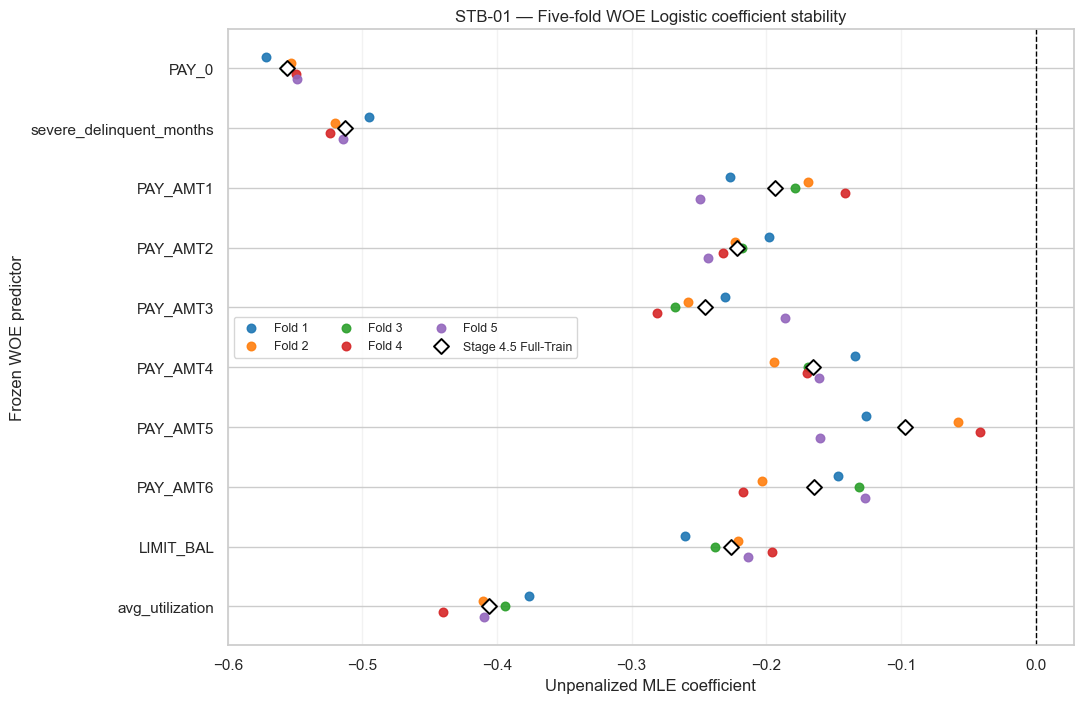

In [10]:
fig, ax = plt.subplots(figsize=(11, 7.2))
y_base = np.arange(len(FINAL_PREDICTORS))
offsets = np.linspace(-0.18, 0.18, 5)
fold_colors = sns.color_palette("tab10", 5)
for fold in range(1, 6):
    fold_values = coefficient_detail.loc[
        coefficient_detail["Fold"] == fold
    ].set_index("Predictor").loc[FINAL_PREDICTORS, "Coefficient"]
    ax.scatter(fold_values, y_base + offsets[fold - 1], s=38, color=fold_colors[fold - 1], label=f"Fold {fold}", alpha=0.9)
full_reference = np.array([STAGE45_COEFFICIENTS[predictor] for predictor in FINAL_PREDICTORS])
ax.scatter(full_reference, y_base, marker="D", s=58, facecolor="white", edgecolor="black", linewidth=1.4, label="Stage 4.5 Full-Train")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(y_base, FINAL_PREDICTORS)
ax.invert_yaxis()
ax.set_xlabel("Unpenalized MLE coefficient")
ax.set_ylabel("Frozen WOE predictor")
ax.set_title("STB-01 — Five-fold WOE Logistic coefficient stability")
ax.legend(ncol=3, fontsize=9, loc="best")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)
STB_01_STATUS = "PRESENT — five fold estimates plus Stage 4.5 reference for all ten predictors"


## 9. Five-fold Validation AUC/KS and summary

Fold metrics use only each fold's held-out Validation predictions. KS is `max(TPR − FPR)` with `Default=1`; any recorded KS-max threshold is diagnostic only.


In [11]:
fold_performance = pd.DataFrame(fold_performance_rows)
assert fold_performance.shape == (5, 6)
assert fold_performance["Validation N"].eq(4800).all()
fold_performance_summary = pd.DataFrame({
    "Mean": [fold_performance["AUC"].mean(), fold_performance["KS"].mean()],
    "Sample SD (ddof=1)": [fold_performance["AUC"].std(ddof=1), fold_performance["KS"].std(ddof=1)],
    "Minimum": [fold_performance["AUC"].min(), fold_performance["KS"].min()],
    "Maximum": [fold_performance["AUC"].max(), fold_performance["KS"].max()],
}, index=["Validation AUC", "Validation KS"])
display(fold_performance.style.format({
    "Validation Bad Rate": "{:.6%}", "AUC": "{:.6f}", "KS": "{:.6f}",
    "KS-max Threshold (diagnostic only)": "{:.6f}",
}))
display(fold_performance_summary.style.format("{:.6f}"))


,Fold,Validation N,Validation Bad Rate,AUC,KS,KS-max Threshold (diagnostic only)
0,1,4800,22.104167%,0.776925,0.448389,0.237424
1,2,4800,22.125000%,0.773682,0.437295,0.225276
2,3,4800,22.125000%,0.765526,0.429064,0.182235
3,4,4800,22.125000%,0.767138,0.427996,0.212391
4,5,4800,22.125000%,0.773807,0.438353,0.201543


,Mean,Sample SD (ddof=1),Minimum,Maximum
Validation AUC,0.771415,0.004853,0.765526,0.776925
Validation KS,0.436219,0.008256,0.427996,0.448389


## 10. Complete 24,000-row out-of-fold structure and coverage audit

Every OOF probability comes from the fold model and Fold-Train-only WOE mapping that excluded that observation. The structure remains in Notebook memory and is not exported.


In [12]:
oof = pd.concat(oof_parts, ignore_index=True).sort_values("Development Position").reset_index(drop=True)
expected_ids_in_order = development_raw[ID_COL].astype(int).reset_index(drop=True)
expected_target_in_order = development_raw[TARGET].astype(int).reset_index(drop=True)
assert len(oof) == 24000
assert oof["Development Position"].tolist() == list(range(24000))
assert oof["ID"].reset_index(drop=True).equals(expected_ids_in_order)
assert oof["True Target"].reset_index(drop=True).equals(expected_target_in_order)
assert oof["ID"].nunique() == 24000 and not oof["ID"].duplicated().any()
assert oof["Predicted Probability"].notna().all() and np.isfinite(oof["Predicted Probability"]).all()
assert ((oof["Predicted Probability"] > 0) & (oof["Predicted Probability"] < 1)).all()
assert sorted(oof["Fold"].unique().tolist()) == [1, 2, 3, 4, 5]
assert oof["Excluded from Fold-Train"].all() and oof["WOE Source"].eq("Fold-Train only").all()

oof_coverage_audit = pd.DataFrame({"Actual": [
    len(oof), oof["ID"].nunique(), int(oof["Predicted Probability"].isna().sum()),
    int(oof["ID"].duplicated().sum()), oof["ID"].reset_index(drop=True).equals(expected_ids_in_order),
    oof["True Target"].reset_index(drop=True).equals(expected_target_in_order),
    sorted(oof["Fold"].unique().tolist()), bool(oof["Excluded from Fold-Train"].all()),
    bool(oof["WOE Source"].eq("Fold-Train only").all()),
]}, index=[
    "OOF rows", "Unique IDs", "Missing predictions", "Duplicate OOF IDs",
    "ID/order matches Development Train", "Target matches Development Train", "Fold labels",
    "Excluded from own fold model", "Fold-Train-only WOE source",
])
display(oof_coverage_audit)


,Actual
OOF rows,24000
Unique IDs,24000
Missing predictions,0
Duplicate OOF IDs,0
ID/order matches Development Train,True
Target matches Development Train,True
Fold labels,"[1, 2, 3, 4, 5]"
Excluded from own fold model,True
Fold-Train-only WOE source,True


## 11. Pooled OOF AUC and STB-02

Pooled OOF AUC is calculated once across all 24,000 OOF predictions. It is not the arithmetic mean of fold AUCs and includes cross-fold ranking comparisons.


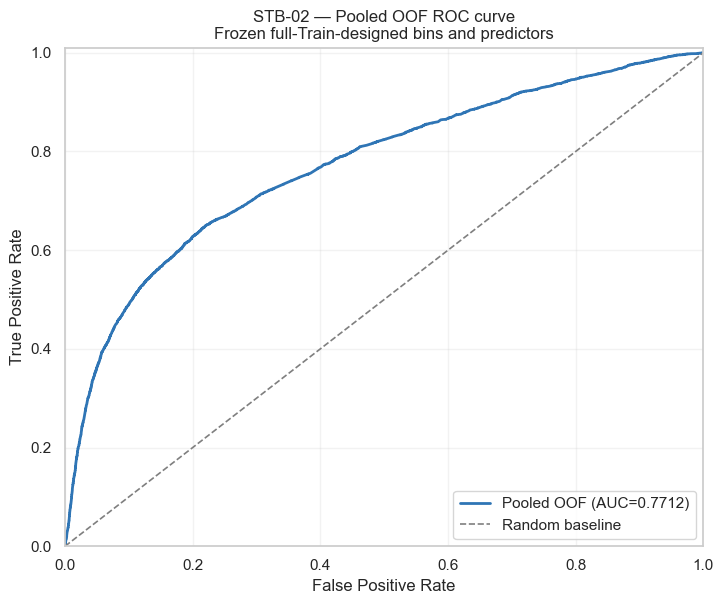

Pooled OOF AUC: 0.771230165


In [13]:
oof_target = oof["True Target"].astype(int)
oof_probability = oof["Predicted Probability"].astype(float)
pooled_oof_auc = float(roc_auc_score(oof_target, oof_probability))
oof_fpr, oof_tpr, oof_thresholds = roc_curve(oof_target, oof_probability, pos_label=1)

fig, ax = plt.subplots(figsize=(7.4, 6.2))
ax.plot(oof_fpr, oof_tpr, color="#2F75B5", linewidth=2, label=f"Pooled OOF (AUC={pooled_oof_auc:.4f})")
ax.plot([0, 1], [0, 1], color="#7F7F7F", linestyle="--", linewidth=1.2, label="Random baseline")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("STB-02 — Pooled OOF ROC curve\nFrozen full-Train-designed bins and predictors")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)
STB_02_STATUS = "PRESENT — pooled 24,000-row OOF ROC with AUC and random reference"
print(f"Pooled OOF AUC: {pooled_oof_auc:.9f}")


## 12. Pooled OOF KS and STB-03

Pooled OOF KS is calculated once as `max(TPR − FPR)` across all OOF predictions. It is not mean fold KS. The maximum-KS threshold is a metric diagnostic location only.


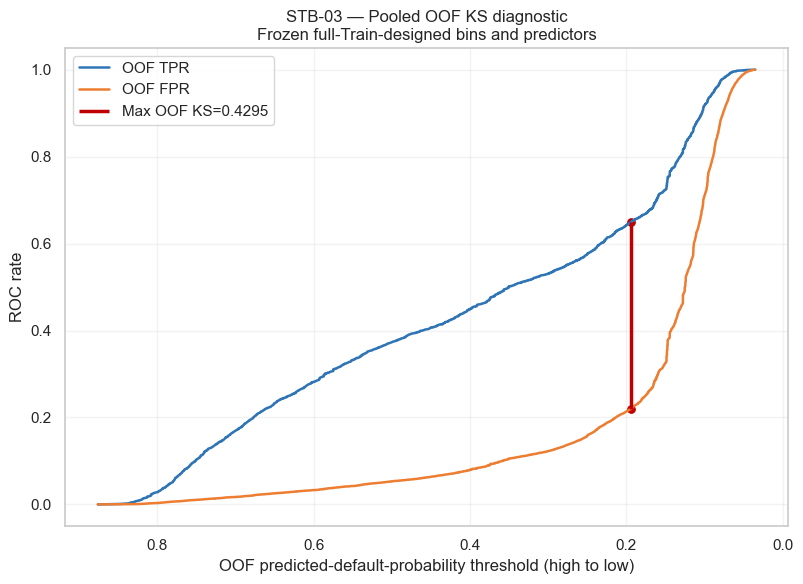

Pooled OOF KS: 0.429462039
OOF KS-max threshold (diagnostic only): 0.194182078


In [14]:
oof_ks_gap = oof_tpr - oof_fpr
oof_ks_index = int(np.argmax(oof_ks_gap))
pooled_oof_ks = float(oof_ks_gap[oof_ks_index])
oof_ks_diagnostic_threshold = float(oof_thresholds[oof_ks_index])
valid_threshold_mask = np.isfinite(oof_thresholds) & (oof_thresholds >= 0) & (oof_thresholds <= 1)

fig, ax = plt.subplots(figsize=(8.2, 6.0))
ax.plot(oof_thresholds[valid_threshold_mask], oof_tpr[valid_threshold_mask], color="#2F75B5", linewidth=1.8, label="OOF TPR")
ax.plot(oof_thresholds[valid_threshold_mask], oof_fpr[valid_threshold_mask], color="#ED7D31", linewidth=1.8, label="OOF FPR")
ax.vlines(
    oof_ks_diagnostic_threshold, oof_fpr[oof_ks_index], oof_tpr[oof_ks_index],
    color="#C00000", linewidth=2.5, label=f"Max OOF KS={pooled_oof_ks:.4f}",
)
ax.scatter(
    [oof_ks_diagnostic_threshold, oof_ks_diagnostic_threshold],
    [oof_fpr[oof_ks_index], oof_tpr[oof_ks_index]], color="#C00000", s=28,
)
ax.invert_xaxis()
ax.set_xlabel("OOF predicted-default-probability threshold (high to low)")
ax.set_ylabel("ROC rate")
ax.set_title("STB-03 — Pooled OOF KS diagnostic\nFrozen full-Train-designed bins and predictors")
ax.legend(loc="best")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)
STB_03_STATUS = "PRESENT — pooled OOF TPR/FPR separation with maximum KS highlighted"
print(f"Pooled OOF KS: {pooled_oof_ks:.9f}")
print(f"OOF KS-max threshold (diagnostic only): {oof_ks_diagnostic_threshold:.9f}")


## 13. Stage 4.5 apparent-minus-OOF gaps

Signed gaps are optimism diagnostics only. No pass/fail cutoff is imposed.


In [15]:
apparent_minus_oof_auc_gap = float(STAGE45_APPARENT_AUC - pooled_oof_auc)
apparent_minus_oof_ks_gap = float(STAGE45_APPARENT_KS - pooled_oof_ks)
gap_table = pd.DataFrame({
    "Stage 4.5 Apparent": [STAGE45_APPARENT_AUC, STAGE45_APPARENT_KS],
    "Stage 4.6 Pooled OOF": [pooled_oof_auc, pooled_oof_ks],
    "Apparent − OOF Gap": [apparent_minus_oof_auc_gap, apparent_minus_oof_ks_gap],
}, index=["AUC", "KS"])
display(gap_table.style.format("{:.9f}"))


,Stage 4.5 Apparent,Stage 4.6 Pooled OOF,Apparent − OOF Gap
AUC,0.772417098,0.771230165,0.001186933
KS,0.430307867,0.429462039,0.000845828


## 14. Required OOF methodological limitation

Stage 4.6 OOF predictions are stronger evidence than Stage 4.5 apparent predictions because each observation is excluded from its fold-specific WOE estimation and Logistic fitting.

However, **Stage 4.6 is not a fully nested, leakage-free model-development estimate**: Stage 4.2/4.3 supervised bin boundaries and Stage 4.4 candidate selection were developed using the full 24,000-row Development Train. Validation-fold observations therefore influenced those earlier design-level decisions.

> Stage 4.6 OOF metrics are model-stability / cross-validated evidence under frozen full-Train-designed bins and predictors, not a final unbiased estimate of unseen-data performance.

The truly sealed unseen-data evaluation remains the Stage 5 Holdout Test.


## 15. PAY_AMT5 focused stability review

PAY_AMT5 enters without a predetermined conclusion. The table reports five coefficients, sign counts, CI evidence, mean, sample SD, range, and deviation from the Stage 4.5 coefficient. This is observational evidence for Stage 4.7 only.


In [16]:
pay_amt5_detail = coefficient_detail.loc[
    coefficient_detail["Predictor"] == "PAY_AMT5",
    ["Fold", "Coefficient", "Sign Check", "Standard Error", "p-value", "95% CI Lower", "95% CI Upper", "Directionally Clear?"],
].copy()
pay_amt5_summary = coefficient_stability_summary.loc[
    coefficient_stability_summary["Predictor"] == "PAY_AMT5"
].copy()
assert len(pay_amt5_detail) == 5 and len(pay_amt5_summary) == 1
display(pay_amt5_detail)
display(pay_amt5_summary)
print("Stage 4.5 PAY_AMT5 coefficient:", STAGE45_COEFFICIENTS["PAY_AMT5"])
print("Focused-review boundary: evidence only; no removal decision.")


,Fold,Coefficient,Sign Check,Standard Error,p-value,95% CI Lower,95% CI Upper,Directionally Clear?
6,1,-0.125774,Expected,0.086177,0.144435,-0.294678,0.043131,No
16,2,-0.057477,Expected,0.089118,0.518956,-0.232146,0.117192,No
26,3,-0.098118,Expected,0.088117,0.265496,-0.270824,0.074589,No
36,4,-0.041387,Expected,0.091442,0.650832,-0.220611,0.137836,No
46,5,-0.160361,Expected,0.084187,0.056804,-0.325365,0.004643,No


,Predictor,Stage 4.5 Full-Train Coefficient,Fold 1 Coefficient,Fold 2 Coefficient,Fold 3 Coefficient,Fold 4 Coefficient,Fold 5 Coefficient,Fold Mean Coefficient,Fold Coefficient SD,Fold Minimum,Fold Maximum,Negative Fold Count,Positive Fold Count,Directionally Clear Fold Count,CI-Crosses-Zero Fold Count,Maximum Absolute Deviation from Full-Train Coefficient,Stage 4.7 Review Note
6,PAY_AMT5,-0.097122,-0.125774,-0.057477,-0.098118,-0.041387,-0.160361,-0.096623,0.048729,-0.160361,-0.041387,5,0,0,5,0.063239,5/5 negative; 5/5 CIs cross zero; review condi...


Stage 4.5 PAY_AMT5 coefficient: -0.09712243714942834
Focused-review boundary: evidence only; no removal decision.


## 16. Family stability views

The same sign, spread, and CI evidence is shown for current/persistent delinquency, the other five PAY_AMT variables, and LIMIT_BAL/avg_utilization. Dropped Stage 4.4 variables are not reopened.


In [17]:
display(coefficient_stability_summary.loc[
    coefficient_stability_summary["Predictor"].isin(["PAY_0", "severe_delinquent_months"])
])
display(coefficient_stability_summary.loc[
    coefficient_stability_summary["Predictor"].isin(["PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT6"])
])
display(coefficient_stability_summary.loc[
    coefficient_stability_summary["Predictor"].isin(["LIMIT_BAL", "avg_utilization"])
])


,Predictor,Stage 4.5 Full-Train Coefficient,Fold 1 Coefficient,Fold 2 Coefficient,Fold 3 Coefficient,Fold 4 Coefficient,Fold 5 Coefficient,Fold Mean Coefficient,Fold Coefficient SD,Fold Minimum,Fold Maximum,Negative Fold Count,Positive Fold Count,Directionally Clear Fold Count,CI-Crosses-Zero Fold Count,Maximum Absolute Deviation from Full-Train Coefficient,Stage 4.7 Review Note
0,PAY_0,-0.556304,-0.571513,-0.553077,-0.557679,-0.549288,-0.548767,-0.556065,0.009346,-0.571513,-0.548767,5,0,5,0,0.015209,5/5 negative; all fold CIs below zero; directi...
1,severe_delinquent_months,-0.513060,-0.495213,-0.520510,-0.512832,-0.523764,-0.514139,-0.513292,0.011063,-0.523764,-0.495213,5,0,5,0,0.017847,5/5 negative; all fold CIs below zero; directi...


,Predictor,Stage 4.5 Full-Train Coefficient,Fold 1 Coefficient,Fold 2 Coefficient,Fold 3 Coefficient,Fold 4 Coefficient,Fold 5 Coefficient,Fold Mean Coefficient,Fold Coefficient SD,Fold Minimum,Fold Maximum,Negative Fold Count,Positive Fold Count,Directionally Clear Fold Count,CI-Crosses-Zero Fold Count,Maximum Absolute Deviation from Full-Train Coefficient,Stage 4.7 Review Note
2,PAY_AMT1,-0.193756,-0.226706,-0.168827,-0.178492,-0.141375,-0.248995,-0.192879,0.043964,-0.248995,-0.141375,5,0,5,0,0.055239,5/5 negative; all fold CIs below zero; directi...
3,PAY_AMT2,-0.222093,-0.198144,-0.223427,-0.217648,-0.232493,-0.243629,-0.223068,0.017046,-0.243629,-0.198144,5,0,5,0,0.023949,5/5 negative; all fold CIs below zero; directi...
4,PAY_AMT3,-0.245401,-0.230898,-0.257929,-0.267996,-0.281390,-0.186212,-0.244885,0.037666,-0.281390,-0.186212,5,0,5,0,0.059189,5/5 negative; all fold CIs below zero; directi...
5,PAY_AMT4,-0.165042,-0.133884,-0.193975,-0.169016,-0.169505,-0.160817,-0.165439,0.021568,-0.193975,-0.133884,5,0,4,1,0.031158,5/5 negative; 1/5 CIs cross zero; review condi...
7,PAY_AMT6,-0.164349,-0.147006,-0.203027,-0.131453,-0.217217,-0.126516,-0.165044,0.042139,-0.217217,-0.126516,5,0,2,3,0.052868,5/5 negative; 3/5 CIs cross zero; review condi...


,Predictor,Stage 4.5 Full-Train Coefficient,Fold 1 Coefficient,Fold 2 Coefficient,Fold 3 Coefficient,Fold 4 Coefficient,Fold 5 Coefficient,Fold Mean Coefficient,Fold Coefficient SD,Fold Minimum,Fold Maximum,Negative Fold Count,Positive Fold Count,Directionally Clear Fold Count,CI-Crosses-Zero Fold Count,Maximum Absolute Deviation from Full-Train Coefficient,Stage 4.7 Review Note
8,LIMIT_BAL,-0.226161,-0.260276,-0.221058,-0.238291,-0.195552,-0.213213,-0.225678,0.024700,-0.260276,-0.195552,5,0,5,0,0.034115,5/5 negative; all fold CIs below zero; directi...
9,avg_utilization,-0.405621,-0.376214,-0.410717,-0.394047,-0.440321,-0.409804,-0.406221,0.023688,-0.440321,-0.376214,5,0,5,0,0.034700,5/5 negative; all fold CIs below zero; directi...


## 17. Stage 4.7 handoff — all ten continue

This table contains no Keep/Drop decision. All ten proceed to Human final-variable review in Stage 4.7.


In [18]:
handoff_columns = [
    "Predictor", "Stage 4.5 Full-Train Coefficient", "Fold Mean Coefficient", "Fold Coefficient SD",
    "Fold Minimum", "Fold Maximum", "Negative Fold Count", "Positive Fold Count",
    "Directionally Clear Fold Count", "CI-Crosses-Zero Fold Count",
    "Maximum Absolute Deviation from Full-Train Coefficient", "Stage 4.7 Review Note",
]
stage47_handoff = coefficient_stability_summary[handoff_columns].copy()
stage47_handoff = stage47_handoff.rename(columns={
    "Fold Minimum": "Fold Min",
    "Fold Maximum": "Fold Max",
    "Negative Fold Count": "Negative Folds / 5",
    "Positive Fold Count": "Positive Folds / 5",
    "Directionally Clear Fold Count": "Directionally Clear Folds / 5",
    "CI-Crosses-Zero Fold Count": "CI-Crosses-Zero Folds / 5",
})
stage47_handoff.insert(11, "Stage 4.5 Status", [STAGE45_STATUS[p] for p in stage47_handoff["Predictor"]])
stage47_handoff.insert(
    12,
    "Stage 4.6 Stability Evidence Summary",
    stage47_handoff.apply(
        lambda row: f"{int(row['Negative Folds / 5'])}/5 negative; {int(row['Directionally Clear Folds / 5'])}/5 directionally clear; {int(row['CI-Crosses-Zero Folds / 5'])}/5 CIs cross zero",
        axis=1,
    ),
)
stage47_handoff["Continuation"] = "Continue to Stage 4.7"
assert stage47_handoff.shape == (10, 15)
assert stage47_handoff["Predictor"].tolist() == FINAL_PREDICTORS
assert stage47_handoff["Continuation"].eq("Continue to Stage 4.7").all()
display(stage47_handoff.style.format({
    "Stage 4.5 Full-Train Coefficient": "{:.6f}", "Fold Mean Coefficient": "{:.6f}",
    "Fold Coefficient SD": "{:.6f}", "Fold Min": "{:.6f}", "Fold Max": "{:.6f}",
    "Maximum Absolute Deviation from Full-Train Coefficient": "{:.6f}",
}))


,Predictor,Stage 4.5 Full-Train Coefficient,Fold Mean Coefficient,Fold Coefficient SD,Fold Min,Fold Max,Negative Folds / 5,Positive Folds / 5,Directionally Clear Folds / 5,CI-Crosses-Zero Folds / 5,Maximum Absolute Deviation from Full-Train Coefficient,Stage 4.5 Status,Stage 4.6 Stability Evidence Summary,Stage 4.7 Review Note,Continuation
0,PAY_0,-0.556304,-0.556065,0.009346,-0.571513,-0.548767,5,0,5,0,0.015209,Directionally Clear,5/5 negative; 5/5 directionally clear; 0/5 CIs cross zero,5/5 negative; all fold CIs below zero; direction stable.,Continue to Stage 4.7
1,severe_delinquent_months,-0.513060,-0.513292,0.011063,-0.523764,-0.495213,5,0,5,0,0.017847,Directionally Clear,5/5 negative; 5/5 directionally clear; 0/5 CIs cross zero,5/5 negative; all fold CIs below zero; direction stable.,Continue to Stage 4.7
2,PAY_AMT1,-0.193756,-0.192879,0.043964,-0.248995,-0.141375,5,0,5,0,0.055239,Directionally Clear,5/5 negative; 5/5 directionally clear; 0/5 CIs cross zero,5/5 negative; all fold CIs below zero; direction stable.,Continue to Stage 4.7
3,PAY_AMT2,-0.222093,-0.223068,0.017046,-0.243629,-0.198144,5,0,5,0,0.023949,Directionally Clear,5/5 negative; 5/5 directionally clear; 0/5 CIs cross zero,5/5 negative; all fold CIs below zero; direction stable.,Continue to Stage 4.7
4,PAY_AMT3,-0.245401,-0.244885,0.037666,-0.281390,-0.186212,5,0,5,0,0.059189,Directionally Clear,5/5 negative; 5/5 directionally clear; 0/5 CIs cross zero,5/5 negative; all fold CIs below zero; direction stable.,Continue to Stage 4.7
5,PAY_AMT4,-0.165042,-0.165439,0.021568,-0.193975,-0.133884,5,0,4,1,0.031158,Directionally Clear,5/5 negative; 4/5 directionally clear; 1/5 CIs cross zero,5/5 negative; 1/5 CIs cross zero; review conditional-strength stability.,Continue to Stage 4.7
6,PAY_AMT5,-0.097122,-0.096623,0.048729,-0.160361,-0.041387,5,0,0,5,0.063239,Review in Stage 4.6,5/5 negative; 0/5 directionally clear; 5/5 CIs cross zero,5/5 negative; 5/5 CIs cross zero; review conditional-strength stability.,Continue to Stage 4.7
7,PAY_AMT6,-0.164349,-0.165044,0.042139,-0.217217,-0.126516,5,0,2,3,0.052868,Directionally Clear,5/5 negative; 2/5 directionally clear; 3/5 CIs cross zero,5/5 negative; 3/5 CIs cross zero; review conditional-strength stability.,Continue to Stage 4.7
8,LIMIT_BAL,-0.226161,-0.225678,0.024700,-0.260276,-0.195552,5,0,5,0,0.034115,Directionally Clear,5/5 negative; 5/5 directionally clear; 0/5 CIs cross zero,5/5 negative; all fold CIs below zero; direction stable.,Continue to Stage 4.7
9,avg_utilization,-0.405621,-0.406221,0.023688,-0.440321,-0.376214,5,0,5,0,0.034700,Directionally Clear,5/5 negative; 5/5 directionally clear; 0/5 CIs cross zero,5/5 negative; all fold CIs below zero; direction stable.,Continue to Stage 4.7


## 18. Mean-fold versus pooled-OOF distinction and final boundaries

- Mean Fold AUC answers how well an individual Validation fold ranked observations on average.
- Pooled OOF AUC is calculated once using all 24,000 OOF predictions and includes cross-fold ranking comparisons.
- They are related but not mathematically identical; the same distinction applies to mean fold KS and pooled OOF KS.

No variable deletion, re-binning, Full-Train WOE leakage, alternative subset, regularization, class weighting/resampling, calibration, operational threshold optimization, or Holdout predictive analysis occurred. This stage does not perform Stage 4.7 selection.


In [19]:
assert model_fit_count == 5
assert len(coefficient_detail) == 50 and len(coefficient_stability_summary) == 10
assert len(fold_performance) == 5 and len(oof) == 24000
assert zero_support_bin_count == 0
assert stage47_handoff["Continuation"].eq("Continue to Stage 4.7").all()

stage46_results = {
    "project_root": str(project_root),
    "python_executable": sys.executable,
    "python_version": sys.version.split()[0],
    "package_versions": {name: metadata.version(name) for name in [
        "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn", "statsmodels"
    ]},
    "raw_rows": 30000,
    "train_rows": len(development_raw),
    "test_rows_identity_only": 6000,
    "train_id_sha256": train_hash,
    "test_id_sha256": test_hash,
    "holdout_seal_status": HOLDOUT_SEAL_STATUS,
    "development_good": DEVELOPMENT_GOOD,
    "development_bad": DEVELOPMENT_BAD,
    "development_bad_rate": DEVELOPMENT_BAD_RATE,
    "predictors": FINAL_PREDICTORS,
    "fold_configuration": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42)",
    "fold_membership_audit": fold_membership_audit.to_dict(orient="records"),
    "pairwise_disjoint": pairwise_disjoint,
    "validation_union_complete": validation_union_complete,
    "validation_exactly_once": validation_exactly_once,
    "frozen_bins_preserved": True,
    "fold_specific_woe": True,
    "validation_target_used_for_woe": False,
    "full_train_woe_used_for_validation": False,
    "frozen_bin_checks": len(woe_bin_audit),
    "zero_support_bin_count": zero_support_bin_count,
    "zero_class_bin_count": zero_class_bin_count,
    "smoothing_occurrence_count": smoothing_occurrence_count,
    "smoothing_predictor_table_count": smoothing_predictor_table_count,
    "model_fit_count": model_fit_count,
    "fold_numerical_audit": fold_numerical_audit.to_dict(orient="records"),
    "numerical_warnings": fold_warning_records,
    "coefficient_detail": coefficient_detail.to_dict(orient="records"),
    "coefficient_stability_summary": coefficient_stability_summary.to_dict(orient="records"),
    "fold_performance": fold_performance.to_dict(orient="records"),
    "fold_performance_summary": fold_performance_summary.reset_index(names="Metric").to_dict(orient="records"),
    "oof_rows": len(oof),
    "oof_unique_ids": int(oof["ID"].nunique()),
    "oof_missing_predictions": int(oof["Predicted Probability"].isna().sum()),
    "oof_duplicate_ids": int(oof["ID"].duplicated().sum()),
    "pooled_oof_auc": pooled_oof_auc,
    "pooled_oof_ks": pooled_oof_ks,
    "oof_ks_diagnostic_threshold": oof_ks_diagnostic_threshold,
    "apparent_minus_oof_auc_gap": apparent_minus_oof_auc_gap,
    "apparent_minus_oof_ks_gap": apparent_minus_oof_ks_gap,
    "stb_01_status": STB_01_STATUS,
    "stb_02_status": STB_02_STATUS,
    "stb_03_status": STB_03_STATUS,
    "oof_limitation_documented": True,
    "all_ten_continue_to_stage_4_7": True,
    "prohibited_work_performed": False,
}

display(pd.DataFrame({"Result": [
    "PASS — deterministic five-fold membership generated once and fully audited",
    f"PASS — {len(woe_bin_audit)} frozen-bin checks; zero-support={zero_support_bin_count}; zero-class={zero_class_bin_count}; smoothing rows={smoothing_occurrence_count}",
    "PASS — exactly five fixed unpenalized models; all numerically valid",
    "PASS — complete 50-row coefficient, 10-row stability, 5-row performance, and 24,000-row OOF evidence",
    "PASS — all ten continue to Stage 4.7; no prohibited analysis",
]}, index=["Folds", "WOE gates", "Models", "Outputs", "Boundary"]))
print("STAGE46_RESULT_JSON=" + json.dumps(stage46_results, ensure_ascii=False, sort_keys=True))


,Result
Folds,PASS — deterministic five-fold membership gene...
WOE gates,PASS — 205 frozen-bin checks; zero-support=0; ...
Models,PASS — exactly five fixed unpenalized models; ...
Outputs,"PASS — complete 50-row coefficient, 10-row sta..."
Boundary,PASS — all ten continue to Stage 4.7; no prohi...


STAGE46_RESULT_JSON={"all_ten_continue_to_stage_4_7": true, "apparent_minus_oof_auc_gap": 0.0011869334172670554, "apparent_minus_oof_ks_gap": 0.0008458282092929092, "coefficient_detail": [{"95% CI Lower": -0.6231645135888857, "95% CI Upper": -0.5198612078102101, "Coefficient": -0.5715128606995479, "Directionally Clear?": "Yes", "Expected Sign": "Negative", "Fold": 1, "Predictor": "PAY_0", "Sign Check": "Expected", "Standard Error": 0.02635336837654136, "p-value": 2.7501871907110918e-104, "z-statistic": -21.686520392144033}, {"95% CI Lower": -0.5491474220309553, "95% CI Upper": -0.4412779103351568, "Coefficient": -0.49521266618305604, "Directionally Clear?": "Yes", "Expected Sign": "Negative", "Fold": 1, "Predictor": "severe_delinquent_months", "Sign Check": "Expected", "Standard Error": 0.027518238229543877, "p-value": 2.1017146125361211e-72, "z-statistic": -17.99579835206857}, {"95% CI Lower": -0.33184698158424936, "95% CI Upper": -0.1215645668239132, "Coefficient": -0.226705774204081